<a href="https://colab.research.google.com/github/Mahmoud-analy/train/blob/main/train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd # call pandas library

In [2]:
df=pd.read_csv('train.csv') # read file

In [3]:
print(df.shape) # tell abour rows & columns

(10050, 25)


In [4]:
df.info() # inform about your table

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10050 entries, 0 to 10049
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   ID                               10045 non-null  float64
 1   Tank Failure Pressure (bar)      10043 non-null  float64
 2   Liquid Ratio (%)                 10041 non-null  float64
 3   Tank Width (m)                   10041 non-null  float64
 4   Tank Length (m)                  10041 non-null  float64
 5   Tank Height (m)                  10042 non-null  float64
 6   BLEVE Height (m)                 10040 non-null  float64
 7   Vapour Height (m)                10041 non-null  float64
 8   Vapour Temperature (K)           10022 non-null  float64
 9   Liquid Temperature (K)           10023 non-null  float64
 10  Obstacle Distance to BLEVE (m)   10042 non-null  float64
 11  Obstacle Width (m)               10044 non-null  float64
 12  Obstacle Height (m

In [5]:
df.describe().T #احصائيات وصفية لبيانات الجدول وبتقلب الاعمده صفوف والاحصاءات اعمده

,count,mean,std,min,25%,50%,75%,max
ID,10045.0,8202.729119,2885.998522,3203.000000,5705.000000,8206.000000,10701.00000,13202.000000
Tank Failure Pressure (bar),10043.0,37.899252,225.634505,4.920000,13.730000,22.940000,32.19000,4995.616406
Liquid Ratio (%),10041.0,0.504288,0.228073,0.100000,0.300000,0.510000,0.70000,0.900000
Tank Width (m),10041.0,1.696627,0.764937,0.380000,1.010000,1.620000,2.39000,3.020000
Tank Length (m),10041.0,5.599281,2.596056,0.580000,3.380000,5.620000,7.81000,10.020000
Tank Height (m),10042.0,1.673800,0.751931,0.380000,1.010000,1.610000,2.39000,3.020000
BLEVE Height (m),10040.0,1.023503,0.575464,-0.020000,0.590000,1.010000,1.58000,2.020000
Vapour Height (m),10041.0,0.845691,0.536538,0.180000,0.400000,0.780000,1.20000,2.620000
Vapour Temperature (K),10022.0,396.755388,71.876848,281.210000,336.620000,386.725000,441.96500,573.300000
Liquid Temperature (K),10023.0,343.460330,35.536412,282.950000,312.810000,342.330000,365.32000,424.600000


In [6]:
print(df.isnull().sum())

ID                                  5
Tank Failure Pressure (bar)         7
Liquid Ratio (%)                    9
Tank Width (m)                      9
Tank Length (m)                     9
Tank Height (m)                     8
BLEVE Height (m)                   10
Vapour Height (m)                   9
Vapour Temperature (K)             28
Liquid Temperature (K)             27
Obstacle Distance to BLEVE (m)      8
Obstacle Width (m)                  6
Obstacle Height (m)                 6
Obstacle Thickness (m)              7
Obstacle Angle                      8
Status                              7
Liquid Critical Pressure (bar)     30
Liquid Boiling Temperature (K)     29
Liquid Critical Temperature (K)    30
Sensor ID                           8
Sensor Position Side                8
Sensor Position x                   7
Sensor Position y                   8
Sensor Position z                   9
Target Pressure (bar)              10
dtype: int64


In [7]:
print(df.isnull().sum(axis=1).value_counts())

0     9938
1      102
20      10
Name: count, dtype: int64


In [8]:
df = df[df.isnull().sum(axis=1) <= 5]


In [9]:
print(df.shape)

(10040, 25)


In [10]:
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

In [11]:
print(df.isnull().sum().sum())

0


In [12]:
df = pd.read_csv('train.csv')
df = df[df.isnull().sum(axis=1) <= 5]

num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

print(df.shape)
print(df.isnull().sum().sum())
print(df.dtypes)

(10040, 25)
0
ID                                 float64
Tank Failure Pressure (bar)        float64
Liquid Ratio (%)                   float64
Tank Width (m)                     float64
Tank Length (m)                    float64
Tank Height (m)                    float64
BLEVE Height (m)                   float64
Vapour Height (m)                  float64
Vapour Temperature (K)             float64
Liquid Temperature (K)             float64
Obstacle Distance to BLEVE (m)     float64
Obstacle Width (m)                 float64
Obstacle Height (m)                float64
Obstacle Thickness (m)             float64
Obstacle Angle                     float64
Status                              object
Liquid Critical Pressure (bar)     float64
Liquid Boiling Temperature (K)     float64
Liquid Critical Temperature (K)    float64
Sensor ID                          float64
Sensor Position Side               float64
Sensor Position x                  float64
Sensor Position y                  float

In [13]:
print(df['Status'].value_counts())

Status
Subcooled      6282
Superheated    3683
Subcool          23
subcooled        20
Subcoled         14
Superheat         8
superheated       6
Saperheated       4
Name: count, dtype: int64


In [14]:
status_map = {
    'Subcooled': 'Subcooled', 'subcooled': 'Subcooled',
    'Subcool': 'Subcooled',   'Subcoled': 'Subcooled',
    'Superheated': 'Superheated', 'superheated': 'Superheated',
    'Superheat': 'Superheated',   'Saperheated': 'Superheated'
}

In [16]:
df['Status'] = df['Status'].map(status-map)

In [17]:
print(df['Status'].value_counts())

Status
Subcooled      6339
Superheated    3701
Name: count, dtype: int64


In [19]:
col = 'Tank Failure Pressure (bar)'

In [22]:
print((df[col]> 100) .sum())

50


In [25]:
print(df[df[col] < 100][col].max())

42.18


In [26]:
df = df[df[col] < 100]

In [27]:
print(df.shape)

(9990, 25)


In [28]:
print(df[col].max())

42.18


In [29]:
print(df.duplicated().sum())

50


In [31]:
print(df['ID'].duplicated().sum())

50


In [32]:
df = df.drop_duplicates()

In [33]:
print(df.shape)

(9940, 25)


In [34]:
print(df.duplicated().sum())

0


In [35]:
print(df['ID'].duplicated().sum())

0


In [36]:
corr = df.drop(columns='ID').corr(numeric_only=True)

In [37]:
target_corr = corr['Target Pressure (bar)'].drop('Target Pressure (bar)').sort_values()
print(target_corr.round(3))

Sensor Position x                 -0.281
Obstacle Distance to BLEVE (m)    -0.206
Sensor Position z                 -0.195
Sensor Position y                 -0.190
Liquid Ratio (%)                  -0.140
Obstacle Height (m)               -0.115
Obstacle Width (m)                -0.068
BLEVE Height (m)                  -0.059
Liquid Boiling Temperature (K)    -0.044
Liquid Critical Temperature (K)   -0.044
Obstacle Angle                    -0.031
Obstacle Thickness (m)            -0.014
Sensor Position Side              -0.005
Vapour Temperature (K)            -0.003
Liquid Critical Pressure (bar)     0.044
Tank Width (m)                     0.051
Liquid Temperature (K)             0.064
Tank Failure Pressure (bar)        0.065
Sensor ID                          0.065
Tank Length (m)                    0.164
Tank Height (m)                    0.198
Vapour Height (m)                  0.273
Name: Target Pressure (bar), dtype: float64


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

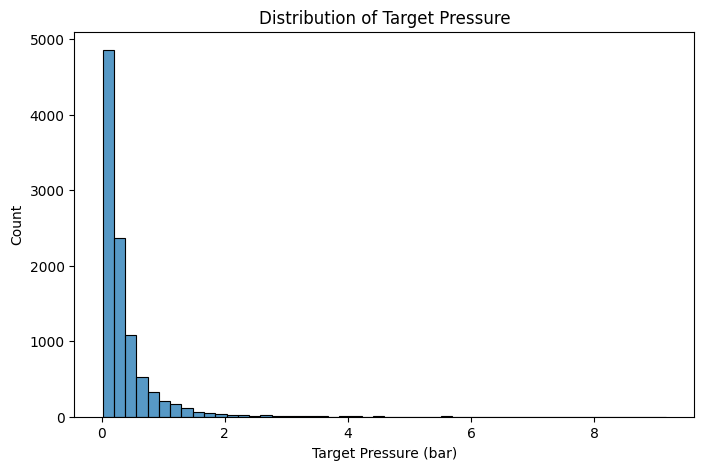

In [39]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Target Pressure (bar)'], bins=50)
plt.title('Distribution of Target Pressure')
plt.xlabel('Target Pressure (bar)')
plt.show()

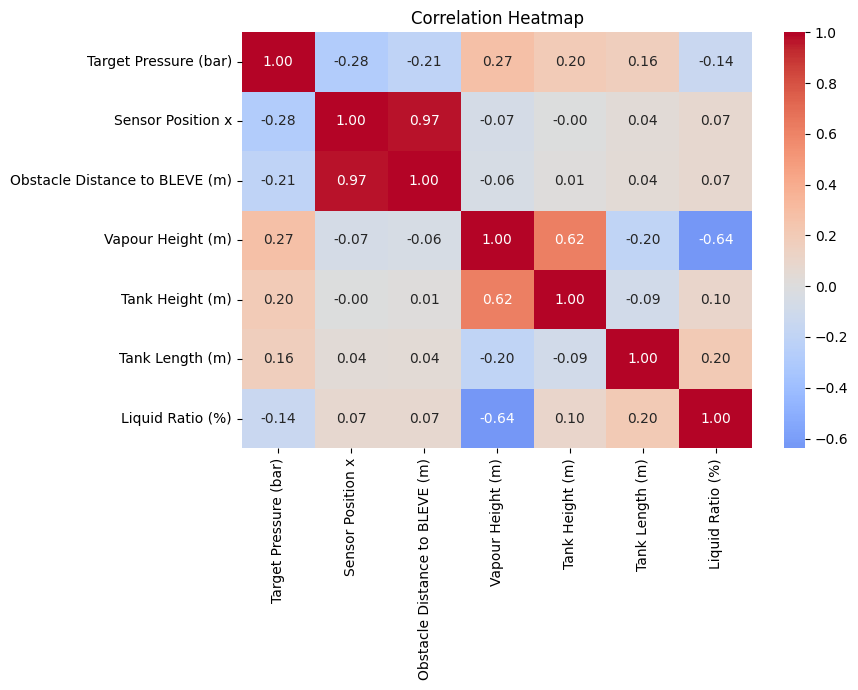

In [40]:
cols = ['Target Pressure (bar)', 'Sensor Position x',
        'Obstacle Distance to BLEVE (m)', 'Vapour Height (m)',
        'Tank Height (m)', 'Tank Length (m)', 'Liquid Ratio (%)']

plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

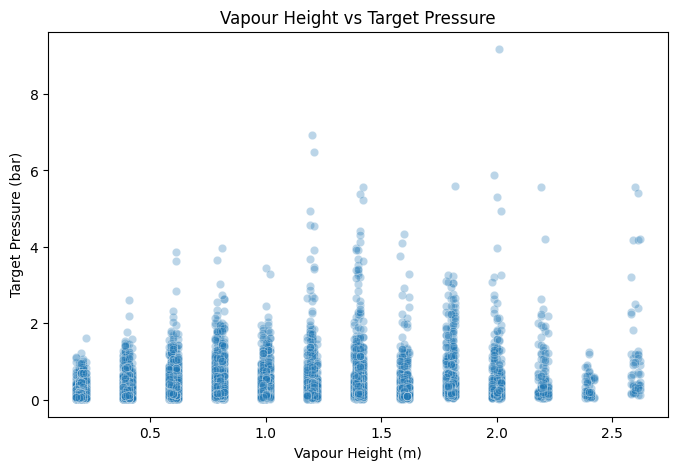

In [41]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Vapour Height (m)', y='Target Pressure (bar)', alpha=0.3)
plt.title('Vapour Height vs Target Pressure')
plt.show()